In [17]:
#Dataset contains risk scores (calculated by Northpointe algorithm) for 7000+ arrests in Broward County, Florida, between 2013 and 2014.
#These risk scores are compared with how many of these individuals were charged for new crimes in the next 2 years (the same analysis used by Northpointe).
import pandas as pd
import matplotlib.pyplot as plt

raw = pd.read_csv("../data/compas-scores-two-years.csv")
print(raw.shape)
raw.head()

(7214, 53)


,id,name,first,last,compas_screening_date,sex,dob,age,age_cat,race,...,v_decile_score,v_score_text,v_screening_date,in_custody,out_custody,priors_count.1,start,end,event,two_year_recid
0,1,miguel hernandez,miguel,hernandez,2013-08-14,Male,1947-04-18,69,Greater than 45,Other,...,1,Low,2013-08-14,2014-07-07,2014-07-14,0,0,327,0,0
1,3,kevon dixon,kevon,dixon,2013-01-27,Male,1982-01-22,34,25 - 45,African-American,...,1,Low,2013-01-27,2013-01-26,2013-02-05,0,9,159,1,1
2,4,ed philo,ed,philo,2013-04-14,Male,1991-05-14,24,Less than 25,African-American,...,3,Low,2013-04-14,2013-06-16,2013-06-16,4,0,63,0,1
3,5,marcu brown,marcu,brown,2013-01-13,Male,1993-01-21,23,Less than 25,African-American,...,6,Medium,2013-01-13,NaN,NaN,1,0,1174,0,0
4,6,bouthy pierrelouis,bouthy,pierrelouis,2013-03-26,Male,1973-01-22,43,25 - 45,Other,...,1,Low,2013-03-26,NaN,NaN,2,0,1102,0,0


In [18]:
#Apply ProPublica's filters
df = raw[
    (raw["days_b_screening_arrest"] <= 30) &
    (raw["days_b_screening_arrest"] >= -30) &
    (raw["is_recid"] != -1) &
    (raw["c_charge_degree"] != "O") &
    (raw["score_text"] != "N/A")
].copy()

print(df.shape)

(6172, 53)


In [19]:
#Check filtering and save cleaned version
df = df[["age", "c_charge_degree", "race", "age_cat", "score_text", "sex",
         "priors_count", "days_b_screening_arrest", "decile_score",
         "is_recid", "two_year_recid"]]

print(df["race"].value_counts())
df.to_csv("../data/compas_clean.csv", index=False)

race
African-American    3175
Caucasian           2103
Hispanic             509
Other                343
Asian                 31
Native American       11
Name: count, dtype: int64


In [4]:
df.head()

,age,c_charge_degree,race,age_cat,score_text,sex,priors_count,days_b_screening_arrest,decile_score,is_recid,two_year_recid
0,69,F,Other,Greater than 45,Low,Male,0,-1.0,1,0,0
1,34,F,African-American,25 - 45,Low,Male,0,-1.0,3,1,1
2,24,F,African-American,Less than 25,Low,Male,4,-1.0,4,1,1
5,44,M,Other,25 - 45,Low,Male,0,0.0,1,0,0
6,41,F,Caucasian,25 - 45,Medium,Male,14,-1.0,6,1,1


In [20]:
# ProPublica treats Medium and High as "high risk" (decile score 5–10)
df["high_risk"] = (df["score_text"] != "Low").astype(int)

# Focus on the two groups ProPublica compares
sub = df[df["race"].isin(["African-American", "Caucasian"])].copy()
print(sub["race"].value_counts())

race
African-American    3175
Caucasian           2103
Name: count, dtype: int64


In [21]:
#rate of recidivism black vs white defendents
sub.groupby("race")["two_year_recid"].mean().round(3)

race
African-American    0.523
Caucasian           0.391
Name: two_year_recid, dtype: float64

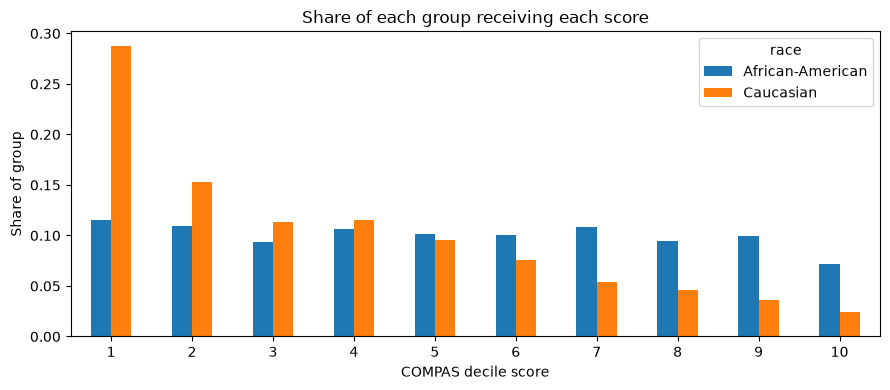

In [22]:
#distribution of recidivism scores among black and white defendents (as a share of total scores)
shares = pd.crosstab(sub["decile_score"], sub["race"], normalize="columns")

ax = shares.plot(kind="bar", figsize=(9, 4), rot=0)
ax.set_xlabel("COMPAS decile score")
ax.set_ylabel("Share of group")
ax.set_title("Share of each group receiving each score")
plt.tight_layout()
plt.savefig("../outputs/score_share_by_race.png", dpi=150)
plt.show()

In [23]:
#We observe that black defendent's scores are relative stable across the deciles.
#However, white defendent's scores are skewed towards lower risk categories.
#This does not necessarily indicate bias as we observed that the actual recidivism rate is high for black defendents than for white defendents (0.523 vs 0.391)
#To investigate potential racial bias, we investigate whether the size of the differences between races in scores are justified by the size of the differences in observed recidivism.

In [24]:
#confusion matrix
def error_rates(g):
    tp = ((g.high_risk == 1) & (g.two_year_recid == 1)).sum()
    fp = ((g.high_risk == 1) & (g.two_year_recid == 0)).sum()
    tn = ((g.high_risk == 0) & (g.two_year_recid == 0)).sum()
    fn = ((g.high_risk == 0) & (g.two_year_recid == 1)).sum()
    return pd.Series({
        "n": len(g),
        "FPR (flagged, didn't reoffend)": fp / (fp + tn),
        "FNR (not flagged, did reoffend)": fn / (fn + tp),
        "PPV (flagged & did reoffend)": tp / (tp + fp),
        "Accuracy": (tp + tn) / len(g),
    })

rates = sub.groupby("race")[["high_risk", "two_year_recid"]].apply(error_rates)
rates.round(3)

,n,"FPR (flagged, didn't reoffend)","FNR (not flagged, did reoffend)",PPV (flagged & did reoffend),Accuracy
race,,,,,
African-American,3175.0,0.423,0.285,0.650,0.649
Caucasian,2103.0,0.220,0.496,0.595,0.672


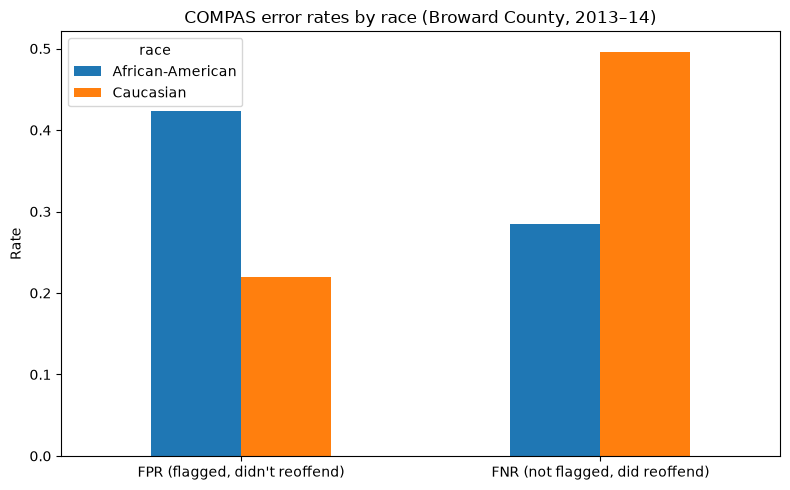

In [8]:
plot_df = rates[["FPR (flagged, didn't reoffend)", "FNR (not flagged, did reoffend)"]].T
ax = plot_df.plot(kind="bar", figsize=(8, 5), rot=0)
ax.set_ylabel("Rate")
ax.set_title("COMPAS error rates by race (Broward County, 2013–14)")
plt.tight_layout()
plt.savefig("../outputs/error_rates_by_race.png", dpi=150)
plt.show()

In [ ]:
#Accuracy is similar across races (64% vs 67%).
#However, black defendants far more likely than white defendants to be incorrectly judged to be at a higher risk of recidivism (0.42 vs 0.22)
#Yet white defendants more likely than black defendants to be incorrectly flagged as low risk (0.29 vs 0.5)
#This suggests a racial bias.

In [12]:
#%pip install statsmodels

Defaulting to user installation because normal site-packages is not writeable
  Obtaining dependency information for statsmodels from https://files.pythonhosted.org/packages/ef/f5/6b550b5c936dd9ec5c859477698b4fcbccc826e9a4a4a52847fa51673357/statsmodels-0.15.0-cp312-cp312-macosx_11_0_arm64.whl.metadata
  Obtaining dependency information for patsy>=0.5.6 from https://files.pythonhosted.org/packages/20/70/cd3cf5cff538323076a879edef02cce6f13f7d75e03d12f211b0a0dbd178/patsy-1.0.3-py2.py3-none-any.whl.metadata
  Obtaining dependency information for formulaic>=1.1.0 from https://files.pythonhosted.org/packages/fc/75/0576b03f7889ad25b5385b4f6c69e0543713425a6f193b056c9b0a2e65ce/formulaic-1.2.2-py3-none-any.whl.metadata
  Obtaining dependency information for interface-meta>=1.2.0 from https://files.pythonhosted.org/packages/a1/d3/20a61a248feb1249cd81f83ce731f0bdf5170ed96a08a298f7081cda9e90/interface_meta-2.0.1-py3-none-any.whl.metadata
  Obtaining dependency information for wrapt>=1.0 from https:

In [16]:
#logistic regression
import statsmodels.formula.api as smf

formula = (
    "high_risk ~ C(race, Treatment('Caucasian'))"
    " + C(sex, Treatment('Male'))"
    " + C(age_cat, Treatment('25 - 45'))"
    " + priors_count"
    " + C(c_charge_degree, Treatment('F'))"
    " + two_year_recid"
)

model = smf.logit(formula, data=df).fit()
print(model.summary())

Optimization terminated successfully.
         Current function value: 0.499708
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              high_risk   No. Observations:                 6172
Model:                          Logit   Df Residuals:                     6160
Method:                           MLE   Df Model:                           11
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                  0.2729
Time:                        09:54:12   Log-Likelihood:                -3084.2
converged:                       True   LL-Null:                       -4241.7
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                                          coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------------------------
Intercept                 

In [15]:
import numpy as np
#odds ratios
odds = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_lower": np.exp(model.conf_int()[0]),
    "ci_upper": np.exp(model.conf_int()[1]),
    "p_value": model.pvalues,
}).round(3)
odds

,odds_ratio,ci_lower,ci_upper,p_value
Intercept,0.218,0.186,0.254,0.000
"C(race, Treatment('Caucasian'))[T.African-American]",1.612,1.407,1.846,0.000
"C(race, Treatment('Caucasian'))[T.Asian]",0.775,0.304,1.980,0.595
"C(race, Treatment('Caucasian'))[T.Hispanic]",0.652,0.507,0.838,0.001
"C(race, Treatment('Caucasian'))[T.Native American]",4.032,0.898,18.097,0.069
"C(race, Treatment('Caucasian'))[T.Other]",0.438,0.319,0.601,0.000
"C(sex, Treatment('Male'))[T.Female]",1.248,1.068,1.458,0.005
"C(age_cat, Treatment('25 - 45'))[T.Greater than 45]",0.258,0.212,0.313,0.000
"C(age_cat, Treatment('25 - 45'))[T.Less than 25]",3.700,3.189,4.294,0.000
"C(c_charge_degree, Treatment('F'))[T.M]",0.733,0.643,0.835,0.000
